# 02 – Modèle Python : YTM, duration, convexité, bootstrap (Groupe 2, Phases 1 et 3)

Toutes les fonctions viennent de `src/pricing.py` (testées par `pytest`).

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import pricing as p
from src.data import load_bonds, bonds_for_bootstrap
FIG = ROOT / 'docs' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})

## 1. Tableau récapitulatif par obligation

In [2]:
df = load_bonds()
rows = []
for r in df.itertuples():
    y = p.ytm_bissection(r.prix_marche, r.coupon, r.nominal, r.maturite)
    rows.append({'Obligation': r.nom, 'T': r.maturite, 'Coupon': r.coupon, 'Prix': r.prix_marche,
                 'YTM (%)': 100*y,
                 'D_Mac (ans)': p.duration_macaulay(y, r.coupon, r.nominal, r.maturite),
                 'D_mod': p.duration_modifiee(y, r.coupon, r.nominal, r.maturite),
                 'Convexité': p.convexite(y, r.coupon, r.nominal, r.maturite)})
tab = pd.DataFrame(rows).set_index('Obligation')
tab.round(4)

,T,Coupon,Prix,YTM (%),D_Mac (ans),D_mod,Convexité
Obligation,,,,,,,
OBL-1A,1,2.0,99.5,2.5126,1.0000,0.9755,1.9032
OBL-2A,2,2.5,99.0,3.0228,1.9755,1.9175,5.5607
OBL-3A,3,3.0,98.8,3.4277,2.9129,2.8164,10.7841
OBL-4A,4,3.3,98.5,3.7104,3.8108,3.6744,17.4251
OBL-5A,5,3.5,98.0,3.9486,4.6692,4.4919,25.3269


In [3]:
tab.round(4).to_csv(ROOT/'docs'/'tableau_recap.csv')
print('D_Mac <= T pour toutes :', bool((tab['D_Mac (ans)'] <= tab['T'] + 1e-12).all()))

D_Mac <= T pour toutes : True


## 2. Bootstrap : courbe zéro-coupon, facteurs d'actualisation, taux forward

In [4]:
bonds = bonds_for_bootstrap(df)
z = p.bootstrap(bonds)
dfac = p.discount_factors(z)
fwd = p.taux_forward(z)
courbe = pd.DataFrame({'z_n (%)': {n: 100*v for n, v in z.items()},
                       'DF_n': dfac,
                       'f(n-1,n) (%)': {k[1]: 100*v for k, v in fwd.items()}})
courbe.index.name = 'n'
courbe.round(4)

,z_n (%),DF_n,"f(n-1,n) (%)"
n,,,
1,2.5126,0.9755,2.5126
2,3.0292,0.9421,3.5485
3,3.4454,0.9034,4.2827
4,3.7397,0.8634,4.6276
5,3.9914,0.8223,5.0042


In [5]:
# Contrôle : réactualiser chaque obligation avec la courbe ZC doit redonner le prix de marché
ctrl = pd.DataFrame([{'T': T, 'Prix marché': P, 'Prix via ZC': p.prix_par_courbe_zc(z, c, 100, T)} for T, c, P in bonds])
ctrl['Écart'] = ctrl['Prix via ZC'] - ctrl['Prix marché']
print('Écart max =', ctrl['Écart'].abs().max())
ctrl.round(8)

Écart max = 4.263256414560601e-14


,T,Prix marché,Prix via ZC,Écart
0,1,99.5,99.5,0.0
1,2,99.0,99.0,0.0
2,3,98.8,98.8,0.0
3,4,98.5,98.5,-0.0
4,5,98.0,98.0,0.0


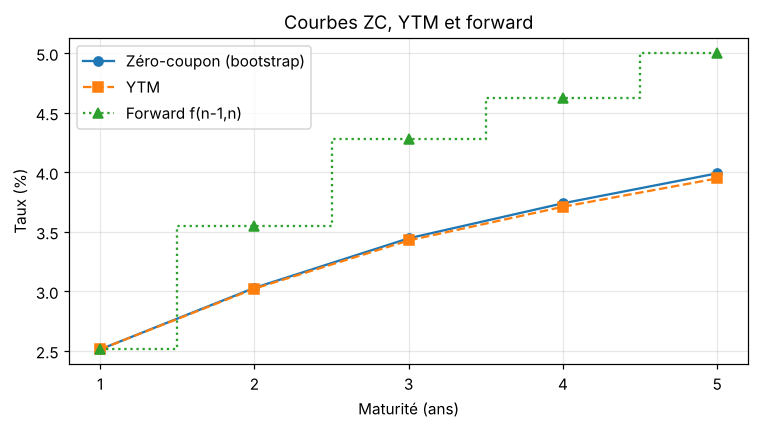

In [6]:
mats = list(z.keys())
fig, ax = plt.subplots(figsize=(7,4))
ax.plot(mats, [100*z[n] for n in mats], 'o-', label='Zéro-coupon (bootstrap)')
ax.plot(tab['T'], tab['YTM (%)'], 's--', label='YTM')
ax.step([k[1] for k in fwd], [100*v for v in fwd.values()], where='mid', marker='^', ls=':', label='Forward f(n-1,n)')
ax.set_xlabel('Maturité (ans)'); ax.set_ylabel('Taux (%)'); ax.set_title('Courbes ZC, YTM et forward')
ax.set_xticks(mats); ax.legend(); plt.tight_layout(); plt.savefig(FIG/'courbes_taux.png'); plt.show()

## 3. Sensibilité à un choc de taux (+1 %)
Comparaison de la variation exacte du prix, de l'approximation par la duration seule, et de l'approximation duration + convexité.

In [7]:
dy = 0.01
res = []
for r, (nom, row) in zip(df.itertuples(), tab.iterrows()):
    y = row['YTM (%)']/100
    res.append({'Obligation': nom,
                'Exact (%)': 100*p.variation_prix_exacte(y, r.coupon, 100, r.maturite, dy),
                'Duration seule (%)': 100*p.variation_prix_approx(y, r.coupon, 100, r.maturite, dy, False),
                'Duration + convexité (%)': 100*p.variation_prix_approx(y, r.coupon, 100, r.maturite, dy, True)})
sens = pd.DataFrame(res).set_index('Obligation')
sens['Erreur duration (pb)'] = 100*(sens['Duration seule (%)'] - sens['Exact (%)'])
sens['Erreur dur.+conv. (pb)'] = 100*(sens['Duration + convexité (%)'] - sens['Exact (%)'])
sens.round(4)

,Exact (%),Duration seule (%),Duration + convexité (%),Erreur duration (pb),Erreur dur.+conv. (pb)
Obligation,,,,,
OBL-1A,-0.9661,-0.9755,-0.9660,-0.9424,0.0092
OBL-2A,-1.8901,-1.9175,-1.8897,-2.7449,0.0355
OBL-3A,-2.7633,-2.8164,-2.7624,-5.3068,0.0852
OBL-4A,-3.5889,-3.6744,-3.5873,-8.5487,0.1639
OBL-5A,-4.3680,-4.4919,-4.3652,-12.3878,0.2756


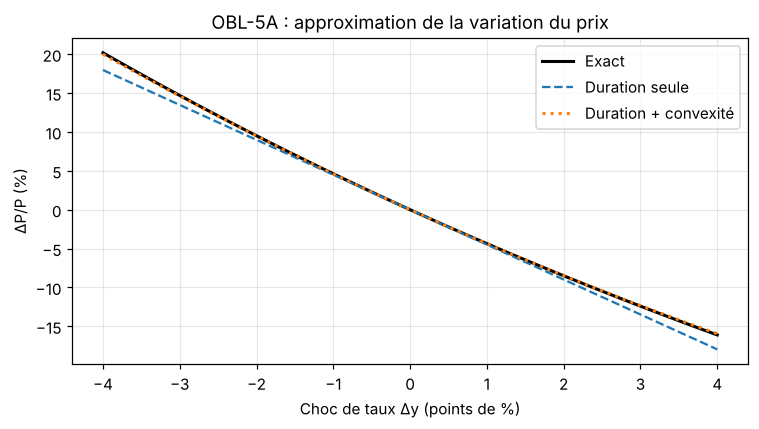

In [8]:
chocs = np.linspace(-0.04, 0.04, 81)
r5 = df.iloc[-1]; y5 = tab.iloc[-1]['YTM (%)']/100
ex = [100*p.variation_prix_exacte(y5, r5.coupon, 100, r5.maturite, d) for d in chocs]
a1 = [100*p.variation_prix_approx(y5, r5.coupon, 100, r5.maturite, d, False) for d in chocs]
a2 = [100*p.variation_prix_approx(y5, r5.coupon, 100, r5.maturite, d, True) for d in chocs]
fig, ax = plt.subplots(figsize=(7,4))
ax.plot(100*chocs, ex, 'k', lw=2, label='Exact'); ax.plot(100*chocs, a1, '--', label='Duration seule'); ax.plot(100*chocs, a2, ':', lw=2, label='Duration + convexité')
ax.set_xlabel('Choc de taux Δy (points de %)'); ax.set_ylabel('ΔP/P (%)'); ax.set_title('OBL-5A : approximation de la variation du prix'); ax.legend()
plt.tight_layout(); plt.savefig(FIG/'sensibilite_choc.png'); plt.show()

## 4. Portefeuille (une unité de chaque obligation)
Duration du portefeuille = moyenne des durations pondérée par les valeurs de marché.

In [9]:
valeurs = tab['Prix'].values
D_ptf = p.duration_portefeuille(tab['D_Mac (ans)'].values, valeurs)
Dm_ptf = p.duration_portefeuille(tab['D_mod'].values, valeurs)
print(f'Valeur du portefeuille : {valeurs.sum():.2f}')
print(f'Duration de Macaulay du portefeuille : {D_ptf:.4f} ans')
print(f'Duration modifiée du portefeuille   : {Dm_ptf:.4f}')

Valeur du portefeuille : 493.80
Duration de Macaulay du portefeuille : 2.8672 ans
Duration modifiée du portefeuille   : 2.7689


## 5. Cas limites vérifiés
- Prix incohérent (hors de l'intervalle de racine) → `ValueError` explicite.
- Maturité manquante dans le bootstrap → `ValueError`.
- Obligation zéro-coupon : duration = maturité.

In [10]:
try:
    p.ytm_bissection(500.0, 2.0, 100, 3)
except ValueError as e:
    print('OK :', e)
print('Duration zéro-coupon T=7 :', p.duration_macaulay(0.03, 0.0, 100, 7))

OK : Pas de racine dans [0.0, 1.0] : f(a)=-394.0000, f(b)=-485.7500
Duration zéro-coupon T=7 : 7.0
